## Pandas analysis

This exercise consists in analyzing a dataset containg timing information from a series of Time-to-Digital-Converters (TDC) implemented in a couple of FPGAs. Each measurement (i.e. each row of the input file) consists of a flag that specifies the type of message ('HEAD', which in this case is always 1), two addresses of the TDC providing the signal ('FPGA' and 'TDC_CHANNEL'), and the timing information ('ORBIT_CNT', 'BX_COUNTER', and 'TDC_MEAS'). Each TDC count corresponds to 25/30 ns, whereas a unit of BX_COUNTER corresponds to 25 ns, and the ORBIT_CNT is increased every 'x' BX_COUNTER. This allows to store the time in a similar way to hours, minutes and seconds.

In [1]:
# If you didn't download it yet, please get the relevant file now!
!wget -O data_000637.txt "https://www.dropbox.com/scl/fi/pkkpoxlm7beasryexpdf8/data_000637.txt?rlkey=rkm2em1v57hewglzelmin21c9&dl=1"

"wget" non è riconosciuto come comando interno o esterno,
 un programma eseguibile o un file batch.


In [2]:
!curl.exe -L -o data_000637.txt "https://www.dropbox.com/scl/fi/pkkpoxlm7beasryexpdf8/data_000637.txt?rlkey=rkm2em1v57hewglzelmin21c9&dl=1"

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100    240 100    240   0      0    260      0                              0
100    240 100    240   0      0    260      0                              0

  0      0   0      0   0      0      0      0           00:01              0
 48 31.64M  48 15.21M   0      0  7.04M      0   00:04   00:02   00:02 14.46M
100 31.64M 100 31.64M   0      0 10.73M      0   00:02   00:02         14.46M
100 31.64M 100 31.64M   0      0 10.73M      0   00:02   00:02         14.46M
100 31.64M 100 31.64M   0      0 10.73M      0   00:02   00:02         14.46M


1\. Create a Pandas DataFrame reading N rows of the 'data_000637.txt' dataset. Choose N to be smaller than or equal to the maximum number of rows and larger that 10k.

2\. Find out the number of BX in a ORBIT (the value 'x').

3\. Find out how much the data taking lasted. You can either make an estimate based on the fraction of the measurements (rows) you read, or perform this check precisely by reading out the whole dataset.

4\. Create a new column with the absolute time in ns (as a combination of the other three columns with timing information).

5\. Replace the values (all 1) of the HEAD column randomly with 0 or 1.

6\. Create a new DataFrame that contains only the rows with HEAD=1.

7\. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

8\. Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)

9\. Count the number of unique orbits. Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139

In [9]:
#1
import pandas as pd

N = 15000  # maggiore di 10.000 e <= numero massimo di righe
df = pd.read_csv("data_000637.txt", nrows=N)
df  #per mostrarla in jupiter


,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
0,1,0,123,3869200167,2374,26
1,1,0,124,3869200167,2374,27
2,1,0,63,3869200167,2553,28
3,1,0,64,3869200167,2558,19
4,1,0,64,3869200167,2760,25
...,...,...,...,...,...,...
14995,1,1,4,3869200316,3399,9
14996,1,1,17,3869200316,3400,15
14997,1,1,10,3869200316,3530,16
14998,1,1,8,3869200316,3533,18


In [12]:
#2

bx_per_orbit = df.groupby("ORBIT_CNT")["BX_COUNTER"].count()
print(bx_per_orbit)
#numero di bxcounter presenti in ogni orbit

bx_distinti_per_orbit = df.groupby("ORBIT_CNT")["BX_COUNTER"].nunique()
print(bx_distinti_per_orbit)
#valori diversi di bx counter presenti in ogni orbit


ORBIT_CNT
3869200167     43
3869200168     85
3869200169    127
3869200170     98
3869200171    109
             ... 
3869200312     90
3869200313     75
3869200314     93
3869200315    136
3869200316     82
Name: BX_COUNTER, Length: 150, dtype: int64
ORBIT_CNT
3869200167    34
3869200168    68
3869200169    95
3869200170    80
3869200171    83
              ..
3869200312    69
3869200313    63
3869200314    79
3869200315    90
3869200316    66
Name: BX_COUNTER, Length: 150, dtype: int64


In [13]:
#3
import pandas as pd

T_ORBIT = 3564 * 25e-9   #tempo per percorrere un'orbita LHC (in secondi)

full_df = pd.read_csv("data_000637.txt")    #leggo l'intero file
delta_orbit_tot = full_df["ORBIT_CNT"].max() - full_df["ORBIT_CNT"].min()  #conta il numero di orbite diverse considerate
durata_totale = delta_orbit_tot * T_ORBIT

print(f"Orbite totali coperte: {delta_orbit_tot}")
print(f"Durata acquisizione (s): {durata_totale:.4f} s")

Orbite totali coperte: 11004
Durata acquisizione (s): 0.9805 s


In [22]:
#4
#la colonna si crea immediatamente su df con il comando df["..."] = ...
#se è già presente una colonna con quel nome, viene sovrascritta.

df["TIME_NS"] = (
    df["ORBIT_CNT"] * 3564 * 25
    + df["BX_COUNTER"] * 25
    + df["TDC_MEAS"] * (25 / 30)
)

df[["ORBIT_CNT", "BX_COUNTER", "TDC_MEAS", "TIME_NS"]].head()    


# df.head() mostra le prime 5 righe (o n righe se specifico tra le tonde), serve a vedere se l'intestazione va bene.
# tra le doppie quadre decido quali colonne mostrare se non le gradisco tutte

,ORBIT_CNT,BX_COUNTER,TDC_MEAS,TIME_NS
0,3869200167,2374,26,3.447457e+14
1,3869200167,2374,27,3.447457e+14
2,3869200167,2553,28,3.447457e+14
3,3869200167,2558,19,3.447457e+14
4,3869200167,2760,25,3.447457e+14


In [25]:
#5
import numpy as np

df["HEAD"] = np.random.randint(0, 2, size=len(df))
df[["HEAD","ORBIT_CNT"]].head(10)

,HEAD,ORBIT_CNT
0,1,3869200167
1,0,3869200167
2,0,3869200167
3,0,3869200167
4,0,3869200167
5,1,3869200167
6,1,3869200167
7,1,3869200167
8,1,3869200167
9,0,3869200167


In [26]:
#6

df_head1 = df[df["HEAD"] == 1]  #il nuovo df ha come struttura df, ma inserisco il vincolo che la colonna HEAD abbia come valore 1

df_head1.head()

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,TIME_NS
0,1,0,123,3869200167,2374,26,3.447457e+14
5,1,0,63,3869200167,2762,4,3.447457e+14
6,1,0,61,3869200167,2772,14,3.447457e+14
7,1,0,139,3869200167,2776,0,3.447457e+14
8,1,0,62,3869200167,2774,21,3.447457e+14


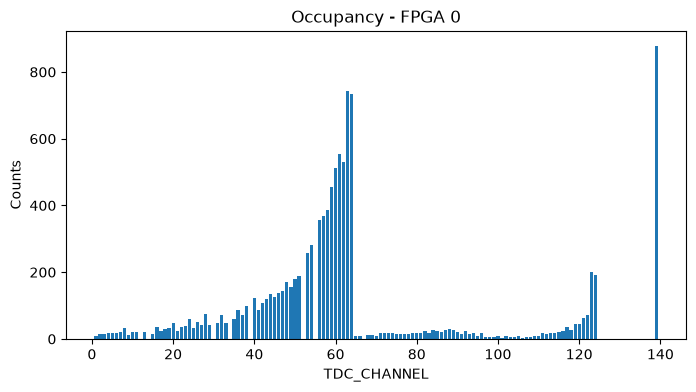

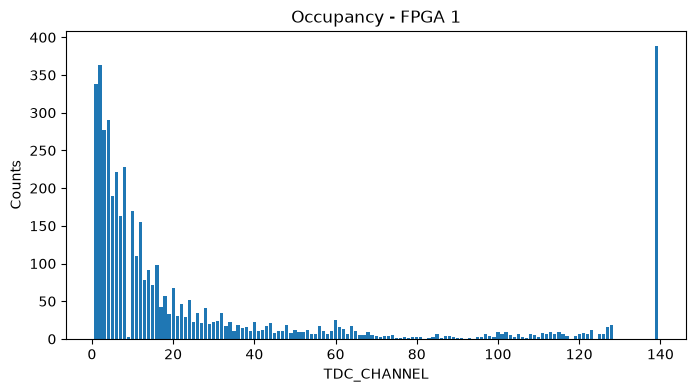

In [30]:
#7
import matplotlib.pyplot as plt

# df.groupby("FPGA") raggruppa i dati per diversi valori nella coonna FPGA (0 e 1)

# quando si itera un for su groupby, viene restituita un coppia: 
# il primo valore (fpga_val) è il valore della colonna per cui si ha raggruppato
# il secondo valore (group) è il sotto dataframe (intero blocco di dati) che contiene tutte le righe che hanno tale valore.
for fpga_val, group in df.groupby("FPGA"):
    counts = group["TDC_CHANNEL"].value_counts().sort_index()

    plt.figure(figsize=(8, 4))
    plt.bar(counts.index, counts.values)
    plt.title(f"Occupancy - FPGA {fpga_val}")
    plt.xlabel("TDC_CHANNEL")
    plt.ylabel("Counts")
    plt.show()

# group["TDC_CHANNEL"]: group è di fatto un sotto dataframe, perciò in questo classico modo seleziono la colonna "TDC_CHANNEL"
# .value_counts(): conta quante volte compare ciascun canale (TDC_CHANNEL). Il risultato è una serie dove l'indice è il numero del canale e il valore è il conteggio.
# .sort_index(): riordina i canali in ordine crescente
# plt.bar(counts.index, counts.values): disegna il grafico a barre 

In [38]:
#8

# Conta le righe per ciascun TDC_CHANNEL
conteggi = df.groupby("TDC_CHANNEL")["TDC_CHANNEL"].count()
# raggruppo per diversi valori di TDC_CHANNEL. Seleziono solo la colonna TDC_CHANNEL (andrebbe bene anche un'altra, tanto basta contare le righe)
# Conto le righe con .count()

top3_channels = conteggi.sort_values(ascending=False).head(3)
#ordino i canali dal più alto al piu baso con ascending=fale. Poi tengo solo i primi 3 selezionandoli con .head(3)

print(top3_channels)

# ATTENZIONE!!!
# .sort_values() ordina i valori, ovvero i conteggi!!  Non i TDC_CHANNEL!!  che invece sarebbero stati ordinati con .sort_index()

TDC_CHANNEL
139    1268
64      752
63      749
Name: TDC_CHANNEL, dtype: int64


In [39]:
#9

# Numero totale di orbite uniche presenti nel dataset
unique_orbits = df["ORBIT_CNT"].nunique()
print(f"Orbite uniche totali: {unique_orbits}")

# Numero di orbite uniche con almeno una misura su TDC_CHANNEL == 139
orbits_ch139 = df[df["TDC_CHANNEL"] == 139]["ORBIT_CNT"].nunique()
#considero df. filtro righe che hanno come valore TDC = 139. Su tali righe, prendo la colonna orbit e conto quelle non uniche.
print(f"Orbite uniche con TDC_CHANNEL == 139: {orbits_ch139}")

Orbite uniche totali: 150
Orbite uniche con TDC_CHANNEL == 139: 150
